In [1]:
import csv
import json
import random
import time
from datetime import datetime, timezone
from email.utils import parsedate_to_datetime
from pathlib import Path

import pandas as pd
import requests
from IPython.display import display, Image

# Часть 1. Сбор данных через REST API

Получим население и ВВП на душу населения за 2020–2022 годы. Столицы добавим из CountriesNow. Одна строка таблицы соответствует стране за один год.

### 1.1. Источники данных вариант 6

| Параметр | World Bank | CountriesNow |
|---|---|---|
| Адрес и версия | https://api.worldbank.org/v2 | https://countriesnow.space/api/v0.1 |
| Эндпоинты | `/country`, `/country/all/indicator/SP.POP.TOTL`, `/country/all/indicator/NY.GDP.PCAP.CD` | `/countries/capital` |
| Авторизация | Не требуется | Не требуется |
| Пагинация | `page`, `per_page`, число страниц и записей в ответе | Один справочник |
| Даты | Год в поле `date` | Дат нет |
| Ключ | Код страны, год и показатель | ISO3 |
| Лимит запросов | Числовой лимит в использованной документации не указан | Числовой лимит не указан |

Ответы приходят в JSON. Между запросами выдерживается пауза 0,6 секунды. Заголовок Retry-After учитывается при наличии.

Схема: API → JSON → таблица → объединение по коду страны → проверки → CSV.

In [2]:
WB = "https://api.worldbank.org/v2"
YEARS = (2020, 2022)
INDICATORS = {"SP.POP.TOTL": "population", "NY.GDP.PCAP.CD": "gdp_per_capita_usd"}
LOG_FIELDS = ["run", "source", "page", "url", "params", "status", "records", "seconds", "timestamp", "attempt", "retry_after", "error"]


def utc_now():
    return datetime.now(timezone.utc).isoformat()


def write_json(path, value):
    path = Path(path)
    temporary = path.with_suffix(path.suffix + ".tmp")
    temporary.write_text(json.dumps(value, ensure_ascii=False, indent=2, allow_nan=False), encoding="utf-8")
    temporary.replace(path)


def record_count(payload):
    if isinstance(payload, list) and len(payload) == 2 and isinstance(payload[0], dict) and "page" in payload[0]:
        return len(payload[1] or [])
    if isinstance(payload, dict) and isinstance(payload.get("data"), list):
        return len(payload["data"])
    return len(payload) if isinstance(payload, list) else 0


def retry_seconds(header, attempt):
    delay = 2 ** (attempt - 1) + random.uniform(0, 0.25)
    if header:
        try:
            server_delay = float(header)
        except ValueError:
            server_delay = (parsedate_to_datetime(header) - datetime.now(timezone.utc)).total_seconds()
        delay = max(delay, server_delay)
    return delay

### 1.2. Получение JSON

Используем одну сессию с User-Agent, Accept и таймаутами. Проверяем статус и Content-Type. Для 429 и 5xx делаем до трёх повторных попыток с увеличением задержки и случайной добавкой. Остальные ошибки выводятся сразу.

Ответы сохраняются в data_raw.jsonl, сведения о запросах — в collection_log.csv.

In [3]:
class ApiClient:
    def __init__(self, folder, pause=0.6, attempts=4):
        self.folder = Path(folder)
        self.folder.mkdir(parents=True, exist_ok=True)
        self.session = requests.Session()
        self.session.headers.update({"User-Agent": "University-Lab3/1.0", "Accept": "application/json"})
        self.pause = pause
        self.attempts = attempts
        self.run = utc_now()
        self.last_request = 0.0
        self.log = []

    def get_json(self, url, params=None, source="api", page=1):
        for attempt in range(1, self.attempts + 1):
            time.sleep(max(0, self.pause - (time.monotonic() - self.last_request)))
            started = time.perf_counter()
            row = dict(run=self.run, source=source, page=page, url=url,
                       params=json.dumps(params or {}, ensure_ascii=False), status=0,
                       records=0, seconds=0, timestamp=utc_now(), attempt=attempt,
                       retry_after="", error="")
            response = None
            try:
                response = self.session.get(url, params=params, timeout=(10, 45))
                row["status"] = response.status_code
                row["retry_after"] = response.headers.get("Retry-After", "")
                if response.status_code == 429 or 500 <= response.status_code <= 599:
                    row["error"] = response.content[:200].decode("utf-8", errors="replace")
                    if attempt == self.attempts:
                        raise RuntimeError(f"HTTP {response.status_code}: {row['error']}")
                else:
                    if not response.ok:
                        raise RuntimeError(f"HTTP {response.status_code}: {response.content[:200]!r}")
                    if "json" not in response.headers.get("Content-Type", "").lower():
                        raise ValueError(f"Ожидался JSON: {response.content[:200]!r}")
                    try:
                        payload = response.json()
                    except ValueError as exc:
                        raise ValueError(f"Некорректный JSON: {response.content[:200]!r}") from exc
                    if isinstance(payload, dict) and (payload.get("error") is True or payload.get("success") is False):
                        raise ValueError(f"Ошибка API: {response.content[:200]!r}")
                    row["records"] = record_count(payload)
                    with (self.folder / "data_raw.jsonl").open("a", encoding="utf-8") as out:
                        out.write(json.dumps({"source": source, "page": page, "params": params,
                                              "timestamp": row["timestamp"], "response": payload}, ensure_ascii=False) + "\n")
                    return payload
            except (requests.RequestException, ValueError, RuntimeError) as exc:
                row["error"] = str(exc)[:300]
                raise
            finally:
                self.last_request = time.monotonic()
                row["seconds"] = round(time.perf_counter() - started, 4)
                self.log.append(row)
                log_path = self.folder / "collection_log.csv"
                exists = log_path.exists()
                with log_path.open("a", encoding="utf-8", newline="") as out:
                    writer = csv.DictWriter(out, fieldnames=LOG_FIELDS)
                    if not exists:
                        writer.writeheader()
                    writer.writerow(row)
            time.sleep(retry_seconds(response.headers.get("Retry-After"), attempt))
        raise RuntimeError("Исчерпаны повторные попытки")

    def close(self):
        self.session.close()

### 1.3. Пагинация

Запрашиваем по 100 записей на странице. Сбор заканчивается по пустому ответу или числу записей из метаданных. max_records и max_pages ограничивают объём. При повторном запуске получаем последний сохранённый год.

In [4]:
def collect_pages(client, endpoint, params=None, page_size=100, max_records=5000, max_pages=100, source="worldbank"):
    """World Bank использует номер страницы; количество учитывается по фактическому ответу."""
    if min(page_size, max_records, max_pages) < 1:
        raise ValueError("Ограничения должны быть положительными")
    rows = []
    for page in range(1, max_pages + 1):
        query = {**(params or {}), "format": "json", "per_page": page_size, "page": page}
        result = client.get_json(f"{WB}/{endpoint}", query, source, page)
        if not (isinstance(result, list) and len(result) == 2 and "page" in result[0]):
            raise ValueError(f"Неожиданная схема World Bank: {str(result)[:200]}")
        metadata, batch = result
        batch = batch or []
        if int(metadata["page"]) != page:
            raise ValueError("API вернул другую страницу")
        if not batch:
            return rows
        rows.extend(batch[:max_records - len(rows)])
        if len(rows) >= int(metadata["total"]) or page >= int(metadata["pages"]):
            return rows
        if len(rows) >= max_records:
            raise RuntimeError("Достигнут max_records до завершения сбора")
    raise RuntimeError("Достигнут max_pages до завершения сбора")


def fetch_indicators(client, previous_state):
    batches = []
    for code in INDICATORS:
        watermark = previous_state.get("watermarks", {}).get(code, YEARS[0])
        start_year = max(YEARS[0], min(int(watermark), YEARS[1]))
        records = collect_pages(client, f"country/all/indicator/{code}",
                                {"date": f"{start_year}:{YEARS[1]}"}, source=code)
        batches.extend(records)
    return batches

### 1.4. Нормализация и объединение

Раскрываем вложенные поля через json_normalize. Региональные агрегаты исключаем по справочнику стран. Столицы присоединяем по коду страны через left merge. Число строк до и после объединения должно совпасть.

In [5]:
def merge_observations(existing, records):
    def key(record):
        return f"{record['country']['id']}|{record['date']}|{record['indicator']['id']}"
    indexed = {key(record): record for record in existing}
    new = updated = 0
    for record in records:
        identity = key(record)
        if identity not in indexed:
            new += 1
        elif indexed[identity].get("value") != record.get("value"):
            updated += 1
        indexed[identity] = record
    return list(indexed.values()), new, updated


def build_table(records, country_records, capitals):
    long = pd.json_normalize(records, sep=".").rename(columns={
        "countryiso3code": "country_code", "date": "year", "indicator.id": "indicator",
        "country.value": "country", "value": "value"})
    # Исключаем записи без кода страны.
    long = long.loc[long["country_code"].ne("")].copy()
    duplicate_count = int(long.duplicated(["country_code", "year", "indicator"]).sum())
    long = long.drop_duplicates(["country_code", "year", "indicator"], keep="last")
    long["year"] = pd.to_numeric(long["year"], errors="raise").astype("int64")
    long["value"] = pd.to_numeric(long["value"], errors="coerce")
    countries = pd.json_normalize(country_records, sep=".")
    countries = countries.loc[countries["region.id"].ne("NA"), ["id", "name", "region.value", "incomeLevel.value"]]
    countries = countries.rename(columns={"id": "country_code", "name": "country", "region.value": "region", "incomeLevel.value": "income_group"})
    wide = long.pivot(index=["country_code", "year"], columns="indicator", values="value").reset_index()
    wide.columns.name = None
    wide = wide.rename(columns=INDICATORS)
    # Оставляем страны и экономики без региональных агрегатов.
    clean = wide.merge(countries, on="country_code", how="inner", validate="many_to_one")
    before = len(clean)
    clean = clean.merge(capitals, on="country_code", how="left", validate="many_to_one", indicator=True)
    join_info = {"before": before, "after": len(clean), "matched": int(clean["_merge"].eq("both").sum()),
                 "unmatched_codes": clean.loc[clean["_merge"].ne("both"), "country_code"].unique().tolist()}
    clean = clean.drop(columns="_merge")
    if len(clean) != before:
        raise ValueError("Соединение изменило число строк")
    clean["period"] = pd.to_datetime(clean["year"].astype(str) + "-01-01", utc=True)
    clean["population_million"] = clean["population"] / 1_000_000
    clean = clean[["country_code", "country", "region", "income_group", "capital", "year", "period", "population", "population_million", "gdp_per_capita_usd"]]
    return clean.sort_values(["country_code", "year"]).reset_index(drop=True), join_info, duplicate_count

### 1.5. Проверки и сохранение

Проверяем полноту полей, дубликаты по стране и году, численность населения, неотрицательность ВВП и диапазон годов. Выбросы ВВП определяем по правилу 1,5 IQR и не удаляем автоматически.

Массив data справочника столиц разворачиваем через record_path и meta. В state.json сохраняем последний год, накопленные наблюдения и результаты запусков.

In [6]:
def check_quality(clean):
    completeness = clean.notna().mean().mul(100).round(2).rename("completeness_pct").rename_axis("field").reset_index()
    checks = {
        "duplicate_country_year": int(clean.duplicated(["country_code", "year"]).sum()),
        "nonpositive_population": int((clean["population"].notna() & clean["population"].le(0)).sum()),
        "negative_gdp_per_capita": int((clean["gdp_per_capita_usd"].notna() & clean["gdp_per_capita_usd"].lt(0)).sum()),
        "future_or_out_of_range_year": int((~clean["year"].between(YEARS[0], min(YEARS[1], datetime.now(timezone.utc).year))).sum()),
    }
    q1, q3 = clean["gdp_per_capita_usd"].quantile([0.25, 0.75])
    outliers = clean.loc[clean["gdp_per_capita_usd"].gt(q3 + 1.5 * (q3 - q1))]
    return completeness, checks, outliers


def run_collection(folder="."):
    folder = Path(folder)
    folder.mkdir(parents=True, exist_ok=True)
    state_path = folder / "state.json"
    state = json.loads(state_path.read_text(encoding="utf-8")) if state_path.exists() else {}
    if state.get("years", list(YEARS)) != list(YEARS):
        raise ValueError("Изменён период. Для нового периода используйте другую папку результатов.")
    started = time.perf_counter()
    client = ApiClient(folder)
    try:
        incoming = fetch_indicators(client, state)
        observations, added, updated = merge_observations(state.get("observations", []), incoming)
        country_records = collect_pages(client, "country", source="worldbank_countries")
        capitals_response = client.get_json("https://countriesnow.space/api/v0.1/countries/capital", source="countriesnow")
        # Разворачиваем массив столиц с метаданными ответа.
        capital_rows = pd.json_normalize(capitals_response, record_path="data", meta=["msg"], sep=".")
        capitals = capital_rows[["iso3", "capital"]].rename(columns={"iso3": "country_code"})
        capitals["capital"] = capitals["capital"].replace("", pd.NA)
        capital_duplicates = int(capitals.duplicated("country_code").sum())
        if capitals.groupby("country_code")["capital"].nunique().gt(1).any():
            raise ValueError("Разные столицы для одного кода страны")
        capitals = capitals.drop_duplicates("country_code")
        clean, join, raw_duplicates = build_table(observations, country_records, capitals)
        completeness, checks, outliers = check_quality(clean)
        if len(clean) < 300:
            raise ValueError(f"Недостаточный объём итоговой таблицы: {len(clean)}")
        if any(checks.values()):
            raise ValueError(f"Проверки качества не пройдены: {checks}")
        clean.to_csv(folder / "data_clean.csv", index=False, encoding="utf-8-sig")
        new_state = {"years": list(YEARS), "watermarks": {code: max(int(r["date"]) for r in observations if r["indicator"]["id"] == code) for code in INDICATORS},
                     "last_successful_run": client.run, "observation_count": len(observations),
                     "record_key": "country.id + date + indicator.id"}
        result = {"run": client.run, "seconds": round(time.perf_counter() - started, 3),
                  "http_requests": len(client.log), "fetched_observations": len(incoming),
                  "new_observations": added, "updated_observations": updated,
                  "clean_rows": len(clean), "countries": int(clean["country_code"].nunique()),
                  "years": list(YEARS), "raw_duplicates": raw_duplicates, "join": join,
                  "capital_duplicates_removed": capital_duplicates,
                  "checks": checks, "outlier_rows": len(outliers)}
        history = state.get("runs", [])
        history.append(result)
        new_state["observations"] = observations
        new_state["runs"] = history
        write_json(state_path, new_state)
        return clean, completeness, result
    finally:
        client.close()

### 1.6. Выполнение сбора

Сбор использует сохранённое состояние. Если state.json отсутствует, загружается весь период. Итоговая таблица сохраняется в data_clean.csv.

In [7]:
BASE = Path.cwd()
clean, completeness, result = run_collection(BASE)
print("Строк:", len(clean))
print("Стран и экономик:", clean["country_code"].nunique())
print("Запросов:", result["http_requests"])
print("Новых наблюдений:", result["new_observations"])
print("Время, с:", result["seconds"])
display(clean.head(5))

Строк: 651
Стран и экономик: 217
Запросов: 10
Новых наблюдений: 0
Время, с: 15.366


,country_code,country,region,income_group,capital,year,period,population,population_million,gdp_per_capita_usd
0,ABW,Aruba,Latin America & Caribbean,High income,Oranjestad,2020,2020-01-01 00:00:00+00:00,108587.0,0.108587,22664.370995
1,ABW,Aruba,Latin America & Caribbean,High income,Oranjestad,2021,2021-01-01 00:00:00+00:00,107700.0,0.107700,26827.344787
2,ABW,Aruba,Latin America & Caribbean,High income,Oranjestad,2022,2022-01-01 00:00:00+00:00,107310.0,0.107310,31000.571380
3,AFG,Afghanistan,"Middle East, North Africa, Afghanistan & Pakistan",Low income,Kabul,2020,2020-01-01 00:00:00+00:00,39068979.0,39.068979,510.787063
4,AFG,Afghanistan,"Middle East, North Africa, Afghanistan & Pakistan",Low income,Kabul,2021,2021-01-01 00:00:00+00:00,40000412.0,40.000412,356.496214


### 1.7. Качество данных

In [8]:
display(completeness)
print("Дубликаты страна–год:", clean.duplicated(["country_code", "year"]).sum())
print("Тип поля period:", clean["period"].dtype)
print("Число стран:", clean["country_code"].nunique())
print("Результат объединения:", result["join"])
print("Логические проверки:", result["checks"])
print("Выбросов ВВП:", result["outlier_rows"])
assert clean["population"].notna().all()
assert not clean.duplicated(["country_code", "year"]).any()
assert len(clean) >= 300

,field,completeness_pct
0,country_code,100.00
1,country,100.00
2,region,100.00
3,income_group,100.00
4,capital,99.08
5,year,100.00
6,period,100.00
7,population,100.00
8,population_million,100.00
9,gdp_per_capita_usd,96.62


Дубликаты страна–год: 0
Тип поля period: datetime64[us, UTC]
Число стран: 217
Результат объединения: {'before': 651, 'after': 651, 'matched': 645, 'unmatched_codes': ['ASM', 'CHI']}
Логические проверки: {'duplicate_country_year': 0, 'nonpositive_population': 0, 'negative_gdp_per_capita': 0, 'future_or_out_of_range_year': 0}
Выбросов ВВП: 50


### 1.8. Повторный запуск

Повторяем сбор. Совпавшие ключи обновляются, новые добавляются. Проверяем, что повторное получение тех же наблюдений не увеличивает число строк.

In [9]:
repeat_clean, repeat_completeness, repeat_result = run_collection(BASE)
display(pd.DataFrame([result, repeat_result])[
    ["run", "http_requests", "new_observations", "updated_observations", "clean_rows", "seconds"]
])
assert repeat_result["new_observations"] == 0
assert len(repeat_clean) == len(clean)
assert not repeat_clean.duplicated(["country_code", "year"]).any()
clean, completeness, result = repeat_clean, repeat_completeness, repeat_result
print("Повторный запуск не создал дубликатов.")

,run,http_requests,new_observations,updated_observations,clean_rows,seconds
0,2026-11-02T06:26:33.739486+00:00,10,0,0,651,15.366
1,2026-11-02T06:27:00.260715+00:00,10,0,0,651,7.196


Повторный запуск не создал дубликатов.


### 1.9. Анализ данных

Сравним население крупнейших стран и медианный ВВП на душу населения по регионам за 2022 год. Медиана рассчитана по странам с известным значением.

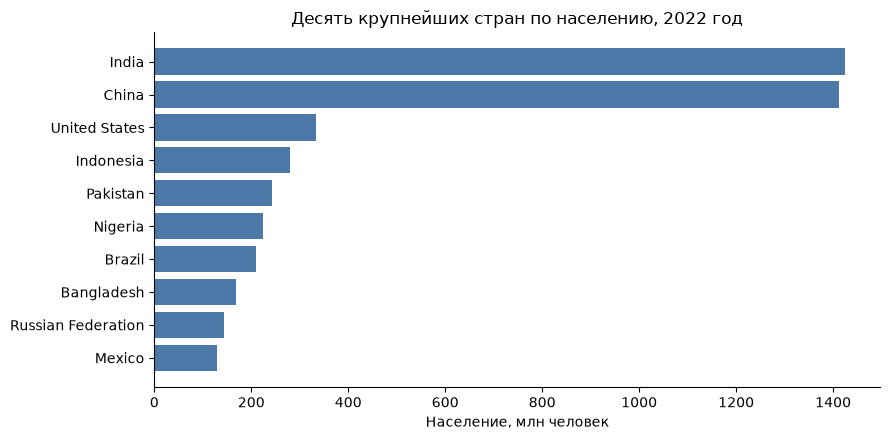

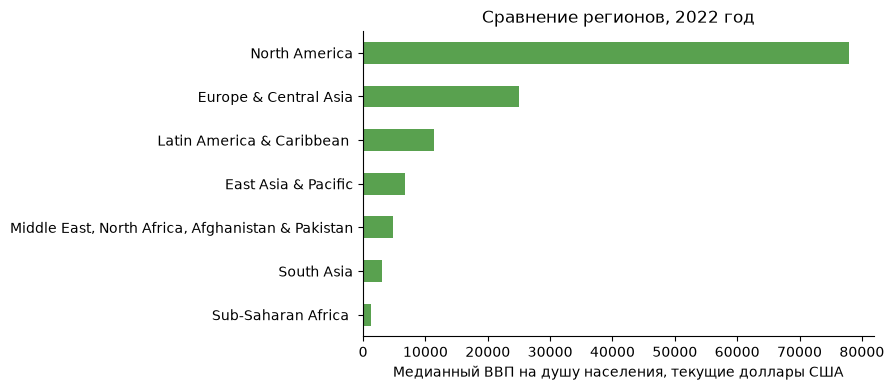

,country,population,gdp_per_capita_usd
269,India,1.425423e+09,2279.981457
110,China,1.412175e+09,12970.605641
611,United States,3.339963e+08,78008.689581
263,Indonesia,2.788305e+08,4730.834848
452,Pakistan,2.437007e+08,1538.322813


In [10]:
import matplotlib.pyplot as plt
plt.rcParams["font.family"] = "DejaVu Sans"
latest = clean[clean["year"] == 2022]
top = latest.nlargest(10, "population").sort_values("population")
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.barh(top["country"], top["population_million"], color="#4c78a8")
ax.set_xlabel("Население, млн человек")
ax.set_title("Десять крупнейших стран по населению, 2022 год")
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
plt.show()
regional = latest.groupby("region")["gdp_per_capita_usd"].median().sort_values()
fig, ax = plt.subplots(figsize=(9, 4))
regional.plot.barh(ax=ax, color="#59a14f")
ax.set_xlabel("Медианный ВВП на душу населения, текущие доллары США")
ax.set_ylabel("")
ax.set_title("Сравнение регионов, 2022 год")
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
plt.show()
display(latest.nlargest(5, "population")[["country", "population", "gdp_per_capita_usd"]])

# Часть 2. Сбор данных в n8n

В nocode/workflow.json сохранён сценарий сбора населения десяти стран за 2020–2022 годы. Получены 30 записей с трёх страниц.

1. Ручной запуск или расписание запускает сценарий.
2. Получить страницы API - выполняет HTTP-запросы с пагинацией по 10 записей.
3. Ответ успешный - проверяет HTTP-статус.
4. Массив записей и Развернуть записи - выделяют отдельные строки.
5. Преобразовать поля - переименовывает поля, переводит год в число и рассчитывает население в миллионах.
6. Создать CSV и Сохранить результат - записывают nocode_result.csv.

Ошибка передаётся в отдельную ветку и сохраняется в error_log.csv. Расписание настроено на 09:00 по Перми. Оно выключено до публикации workflow.

Запуск: импортировать workflow.json и нажать Execute workflow.

### 2.1. Сравнение результатов

В Python получено 651 строка, в n8n - упрощённая выборка из 30. Для сравнения выбираем в Python те же десять стран и пять полей.

In [11]:
countries = ["RUS", "USA", "CHN", "IND", "BRA", "DEU", "FRA", "JPN", "CAN", "AUS"]
fields = ["country_code", "country", "year", "population", "population_million"]
key = ["country_code", "year"]
python_result = clean.loc[clean["country_code"].isin(countries), fields].copy()
nocode_result = pd.read_csv("nocode/nocode_result.csv")

for table in [python_result, nocode_result]:
    for column in ["year", "population", "population_million"]:
        table[column] = pd.to_numeric(table[column], errors="raise")
    assert not table.duplicated(key).any()

print("Полная таблица Python:", len(clean))
print("Выборка Python:", len(python_result))
print("n8n:", len(nocode_result))
print("Общие поля:", fields)
assert len(python_result) == len(nocode_result) == 30
assert set(nocode_result.columns) == set(fields)
pd.testing.assert_frame_equal(
    python_result.sort_values(key).reset_index(drop=True),
    nocode_result[fields].sort_values(key).reset_index(drop=True),
    check_dtype=False, check_exact=True,
)
display(nocode_result.head(5))
print("Все общие поля совпали.")

Полная таблица Python: 651
Выборка Python: 30
n8n: 30
Общие поля: ['country_code', 'country', 'year', 'population', 'population_million']


,country_code,country,year,population,population_million
0,AUS,Australia,2022,26018721,26.018721
1,AUS,Australia,2021,25685412,25.685412
2,AUS,Australia,2020,25649248,25.649248
3,BRA,Brazil,2022,210306415,210.306415
4,BRA,Brazil,2021,209550294,209.550294


Все общие поля совпали.


### 2.2. Сравнение подходов

Ниже приведены сохранённые контрольные замеры от 25.10.2026. Время выполнения измерялось отдельно на одинаковых 30 записях и трёх страницах.

In [12]:
comparison = pd.DataFrame([
    ['Число записей в сравнении', '30', '30'],
    ['Время одного прогона, с', '2.853', '2.106'],
    ['Пагинация', 'Функция, 3 страницы', 'HTTP Request, 3 страницы'],
    ['Ошибки и повторы', 'Журнал; повторы 429/5xx', 'Ветка ошибки; без повторов'],
    ['Воспроизводимость', 'Код, блокнот, requirements.txt', 'Экспорт workflow и Compose'],
    ['100 запусков в месяц', '0 руб. за ПО и API', '0 руб. за ПО и API'],
    ['Порог входа, 1–5', '3 — нужны основы Python', '2 — визуальная сборка'],
], columns=["Критерий", "Python", "n8n"])
display(comparison)

,Критерий,Python,n8n
0,Число записей в сравнении,30,30
1,"Время одного прогона, с",2.853,2.106
2,Пагинация,"Функция, 3 страницы","HTTP Request, 3 страницы"
3,Ошибки и повторы,Журнал; повторы 429/5xx,Ветка ошибки; без повторов
4,Воспроизводимость,"Код, блокнот, requirements.txt",Экспорт workflow и Compose
5,100 запусков в месяц,0 руб. за ПО и API,0 руб. за ПО и API
6,"Порог входа, 1–5",3 — нужны основы Python,2 — визуальная сборка


### 2.3. Скриншоты схемы и выполнения

Первый снимок показывает workflow, второй - успешный запуск. Результат находится в nocode/nocode_result.csv.

nocode/screenshot_workflow.png


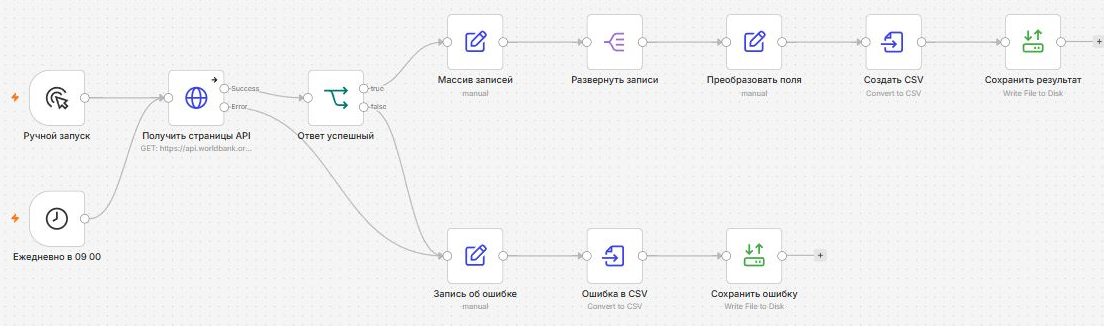

nocode/screenshot_success.png


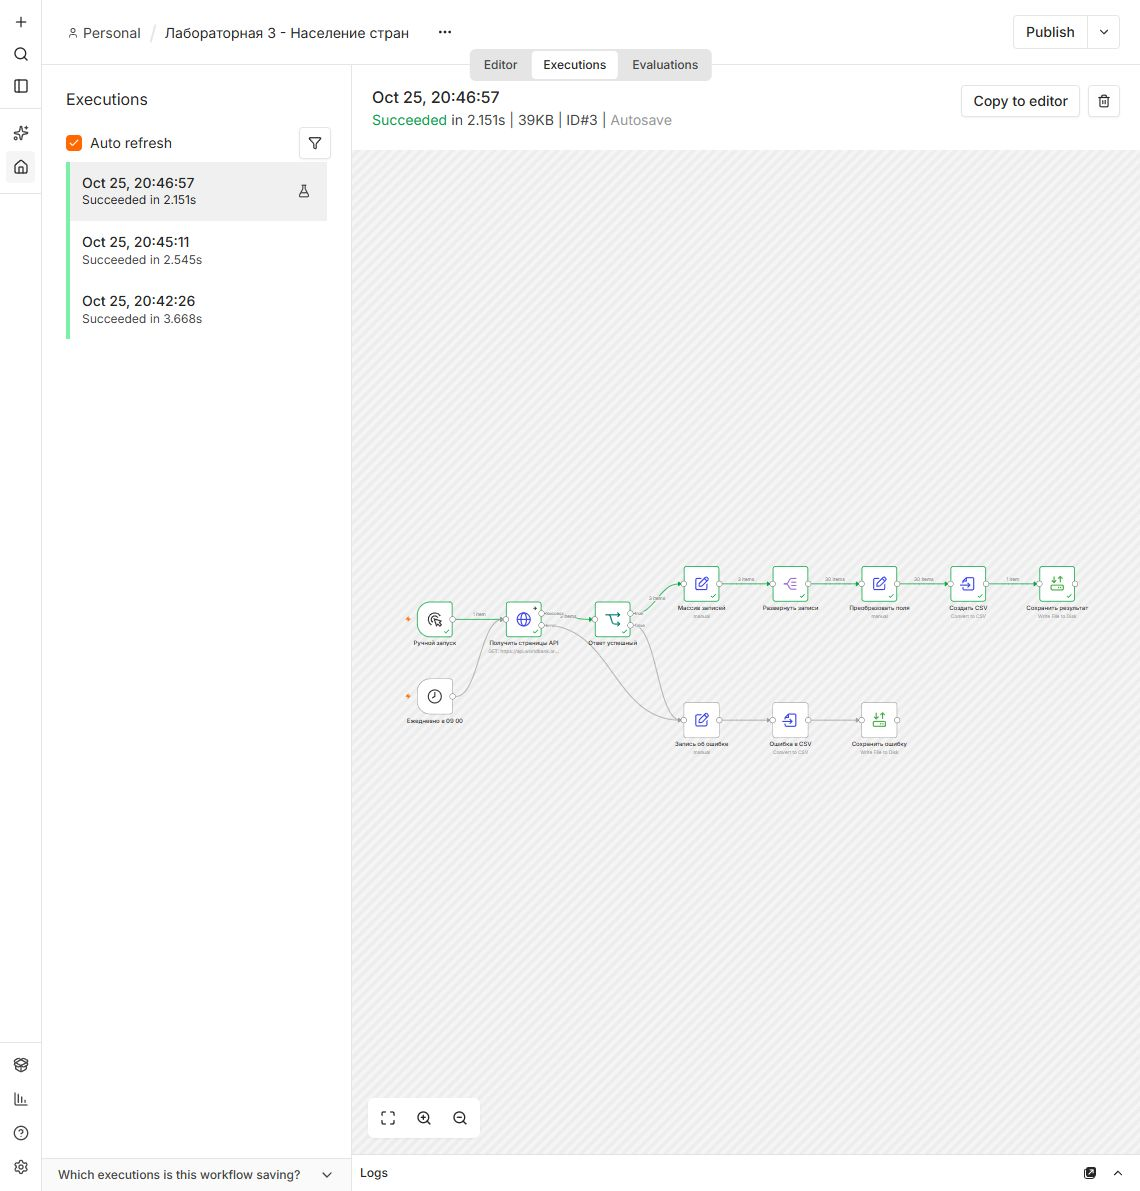

In [13]:
for screenshot in ["nocode/screenshot_workflow.png", "nocode/screenshot_success.png"]:
    print(screenshot)
    display(Image(filename=screenshot, width=1000))

# Итоговый вывод

Собраны показатели 217 стран и экономик за три года — 651 строка. Данные объединены со справочником столиц. Проверены полнота, типы, дубликаты и значения показателей. Повторный запуск не создаёт дубликатов.

В n8n собрана выборка из 30 строк. Значения общих полей совпали с Python. Python удобен для обработки и проверок, n8n - для наглядного сценария с расписанием. Их можно совместить: n8n запускает сбор, Python обрабатывает данные.

Использованы публичные статистические данные и справочник стран.

### Источники

- [World Bank API](https://datahelpdesk.worldbank.org/knowledgebase/articles/898581-api-basic-call-structures)
- [CountriesNow](https://countriesnow.space/) и [исходный проект](https://github.com/MartinsOnuoha/countriesNowAPI)
- [pandas.json_normalize](https://pandas.pydata.org/docs/reference/api/pandas.json_normalize.html)
- [n8n HTTP Request](https://docs.n8n.io/integrations/builtin/core-nodes/n8n-nodes-base.httprequest/)